In [ ]:
%pip install category_encoders
%pip install scikit-learn
%pip install pandas
%pip install numpy
%pip install matplotlib

: 

In [2]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import xgboost as xgb
import lightgbm as lgb
import optuna
import category_encoders as ce
import matplotlib.pyplot as plt
import joblib 
from fastapi import FastAPI
import pandas as pd
from pydantic import BaseModel

C:\Users\LAP ME\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
data = pd.read_csv("Sales_without_NaNs_v1.3.csv")

In [4]:
feature_cols = [
    "Group",
    "Customer_Segment",
    "Sales_Before",
    "Customer_Satisfaction_Before"
]

X = data[feature_cols]
y = data["Sales_After"]

# 2. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
categorical_cols = ["Group", "Customer_Segment"]
numerical_cols = [c for c in feature_cols if c not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_cols,
        ),
        ("num", StandardScaler(), numerical_cols),
    ]
)

# 4. Evaluate Models using Pipelines
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "LightGBM": lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

for name, model in models.items():
    pipeline = Pipeline(
        steps=[("preprocessor", preprocessor), ("regressor", model)]
    )

    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)

    mse = mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    print(f"=== {name} ===")
    print(f"Mean Absolute Error (MAE): {mae:.2f}")
    print(f"Mean Squared Error (MSE):  {mse:.2f}")
    print(f"R^2 Score:                 {r2:.4f}\n")

=== Linear Regression ===
Mean Absolute Error (MAE): 9.90
Mean Squared Error (MSE):  157.07
R^2 Score:                 0.9783

=== Random Forest ===
Mean Absolute Error (MAE): 6.71
Mean Squared Error (MSE):  73.20
R^2 Score:                 0.9899

=== XGBoost ===
Mean Absolute Error (MAE): 6.32
Mean Squared Error (MSE):  68.27
R^2 Score:                 0.9906

=== LightGBM ===
Mean Absolute Error (MAE): 6.30
Mean Squared Error (MSE):  65.63
R^2 Score:                 0.9909



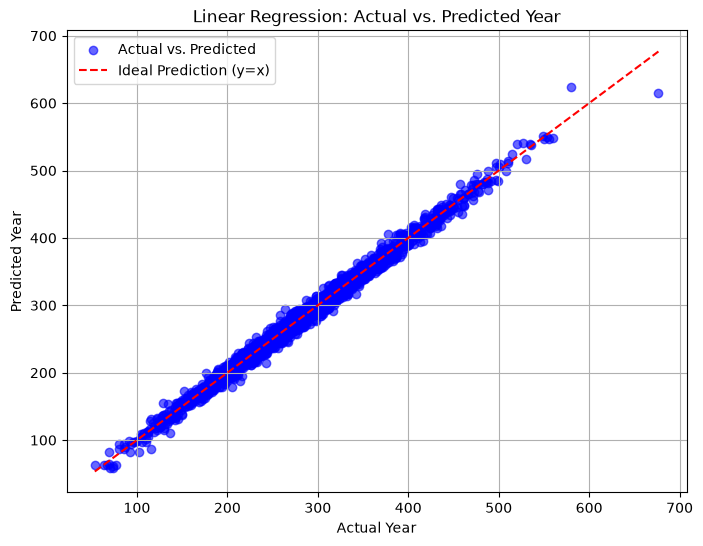

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, preds, alpha=0.6, color='blue', label='Actual vs. Predicted')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Ideal Prediction (y=x)') # Add a 45-degree line for reference
plt.xlabel('Actual Year')
plt.ylabel('Predicted Year')
plt.title('Linear Regression: Actual vs. Predicted Year')
plt.legend()
plt.grid(True)
plt.show()

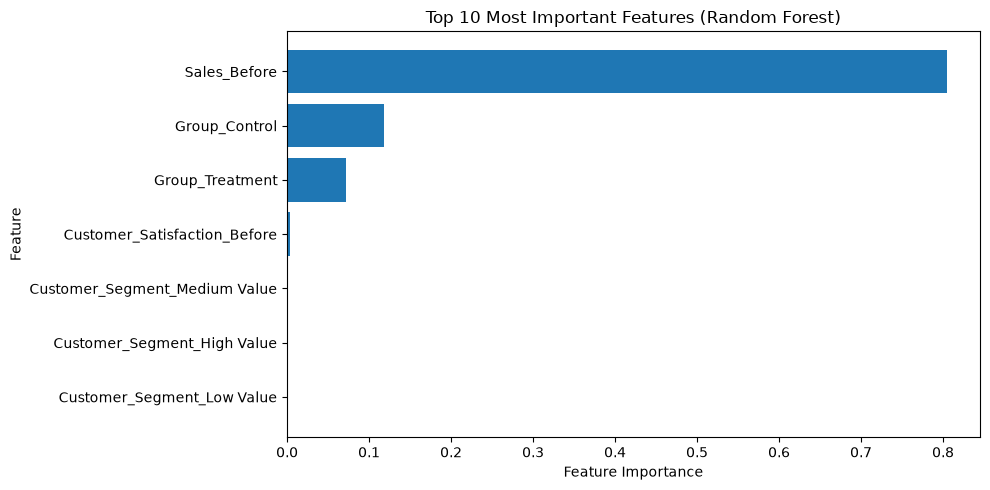

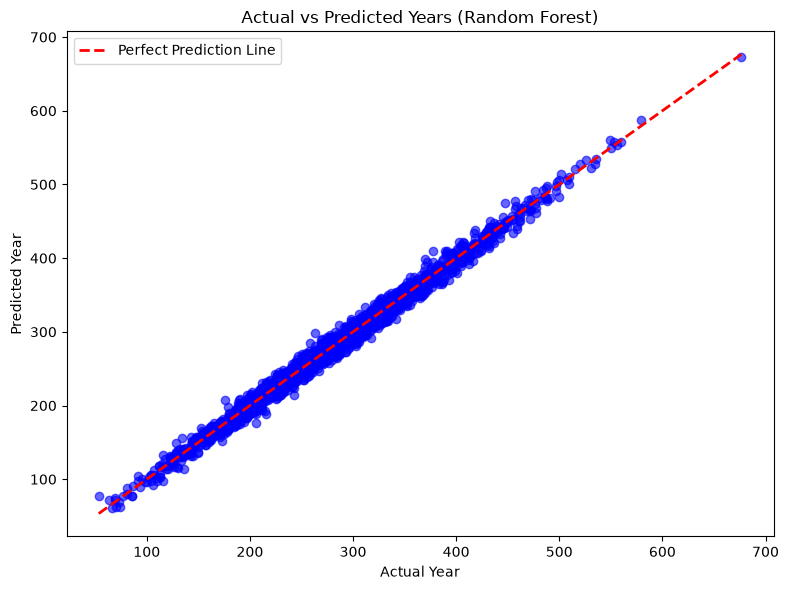

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'regressor__max_depth': 15, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 100}
Tuned MAE: 6.61 years
Tuned R^2: 0.9902

Pipeline saved successfully as 'mental_health_rf_pipeline.pkl'.


In [7]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(n_estimators=100, random_state=42),
        ),
    ]
)
rf_pipeline.fit(X_train, y_train)

# Safely extract feature names from the fitted preprocessor
fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
cat_encoder = fitted_preprocessor.named_transformers_["cat"]
cat_feature_names = list(cat_encoder.get_feature_names_out(categorical_cols))
all_feature_names = cat_feature_names + numerical_cols

# Extract feature importances
importances = rf_pipeline.named_steps["regressor"].feature_importances_

# Create DataFrame & Plot
importance_df = pd.DataFrame(
    {"Feature": all_feature_names, "Importance": importances}
).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(
    importance_df["Feature"].head(10)[::-1],
    importance_df["Importance"].head(10)[::-1],
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Most Important Features (Random Forest)")
plt.tight_layout()
plt.show()

rf_preds = rf_pipeline.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, rf_preds, alpha=0.6, color="blue")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
    label="Perfect Prediction Line",
)
plt.xlabel("Actual Year")
plt.ylabel("Predicted Year")
plt.title("Actual vs Predicted Years (Random Forest)")
plt.legend()
plt.tight_layout()
plt.show()

param_grid = {
    "regressor__n_estimators": [100, 200],
    "regressor__max_depth": [None, 15],
    "regressor__min_samples_split": [2, 5],
}

grid_search = GridSearchCV(
    rf_pipeline, param_grid, cv=3, scoring="neg_mean_squared_error", n_jobs=1 , verbose=1
)
grid_search.fit(X_train, y_train)

best_rf_pipeline = grid_search.best_estimator_
tuned_preds = best_rf_pipeline.predict(X_test)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Tuned MAE: {mean_absolute_error(y_test, tuned_preds):.2f} years")
print(f"Tuned R^2: {r2_score(y_test, tuned_preds):.4f}")

joblib.dump(best_rf_pipeline, "mental_health_rf_pipeline.pkl")
print("\nPipeline saved successfully as 'mental_health_rf_pipeline.pkl'.")

In [8]:
def objective(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
    }
    
    model = xgb.XGBRegressor(**param, random_state=42)
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])
    
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)
    return mean_squared_error(y_test, preds)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=20)

print("Best Trial:")
print(study.best_trial.params)

# Train best model
best_model = xgb.XGBRegressor(**study.best_trial.params, random_state=42)
best_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', best_model)])
best_pipeline.fit(X_train, y_train)

joblib.dump(best_pipeline, 'best_sales_model.pkl')
print("Best model saved as best_sales_model.pkl")

[I 2026-09-28 18:02:32,381] A new study created in memory with name: no-name-2388767c-0667-4ad3-b9a9-b1ffd0a2fdb0
[I 2026-09-28 18:02:33,696] Trial 0 finished with value: 73.71336966169372 and parameters: {'n_estimators': 123, 'max_depth': 7, 'learning_rate': 0.10124519467879509, 'subsample': 0.6967665866577808, 'colsample_bytree': 0.8330215559627411}. Best is trial 0 with value: 73.71336966169372.
[I 2026-09-28 18:02:34,665] Trial 1 finished with value: 83.911475461081 and parameters: {'n_estimators': 117, 'max_depth': 7, 'learning_rate': 0.27619873835812697, 'subsample': 0.9851249430796225, 'colsample_bytree': 0.7883147170022531}. Best is trial 0 with value: 73.71336966169372.
[I 2026-09-28 18:02:35,847] Trial 2 finished with value: 96.40675614056369 and parameters: {'n_estimators': 125, 'max_depth': 10, 'learning_rate': 0.18644927378490855, 'subsample': 0.8286655976835997, 'colsample_bytree': 0.5366590582025556}. Best is trial 0 with value: 73.71336966169372.
[I 2026-09-28 18:02:37,

Best Trial:
{'n_estimators': 249, 'max_depth': 3, 'learning_rate': 0.1910026359123312, 'subsample': 0.680029183178706, 'colsample_bytree': 0.6620202598129838}
Best model saved as best_sales_model.pkl


In [9]:
# Load the saved scikit-learn pipeline
loaded_model = joblib.load("mental_health_rf_pipeline.pkl")

# Make predictions on new data
new_predictions = loaded_model.predict(X_test)
print(new_predictions[:5])

[239.51722621 195.69207702 134.16168192 404.93823235 158.49936664]


In [10]:
app = FastAPI()
model = joblib.load("mental_health_rf_pipeline.pkl")


class InputData(BaseModel):
    Code: str
    Schizophrenia_disorders: float
    Depressive_disorders: float
    Anxiety_disorders: float
    Bipolar_disorders: float


@app.post("/predict")
def predict(data: InputData):
    df = pd.DataFrame([data.dict()])
    prediction = model.predict(df)
    return {"predicted_year": float(prediction[0])}